Construction de l'arbre 
gain(Ciel) = 0.033
gain(Humidité) = 0.300
gain(Vent) = 0.167
→ on choisit Humidité  (Gini 0.500, {'Oui': 4, 'Non': 4})
  branche Humidité = Normale : {'Oui': 4, 'Non': 1}
    gain(Ciel) = 0.053
    gain(Vent) = 0.320
    → on choisit Vent  (Gini 0.320, {'Oui': 4, 'Non': 1})
      branche Vent = Faible : {'Oui': 4}
      branche Vent = Fort : {'Non': 1}
  branche Humidité = Haute : {'Non': 3}

 L'arbre appris 
SI Humidité = Normale :
    SI Vent = Faible :
        → On joue : Oui
    SI Vent = Fort :
        → On joue : Non
SI Humidité = Haute :
    → On joue : Non

Prédictions 
J9 ('Soleil', 'Normale', 'Faible') → Oui
J10 ('Pluie', 'Haute', 'Faible') → Non

 Évaluation (leave-one-out) 
  J1 : vraie = Oui, prédite = Oui  → juste
  J2 : vraie = Non, prédite = Non  → juste
  J3 : vraie = Oui, prédite = Oui  → juste
  J4 : vraie = Non, prédite = Non  → juste
  J5 : vraie = Non, prédite = Non  → juste
  J6 : vraie = Non, prédite = Oui  → FAUX
  J7 : vraie = Oui, pré

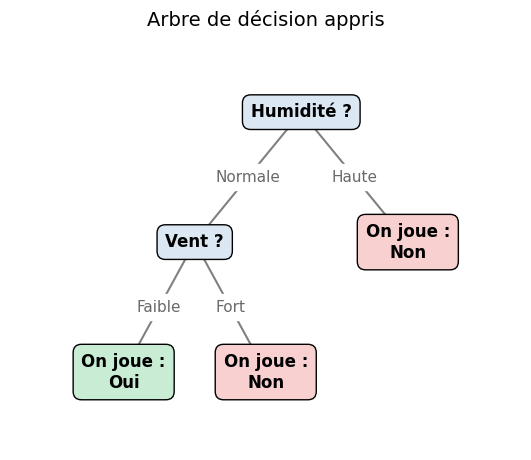

In [1]:


jours = [
    ("Soleil", 65, "Faible", "Oui"),  # J1
    ("Soleil", 90, "Faible", "Non"),  # J2
    ("Pluie",  70, "Faible", "Oui"),  # J3
    ("Soleil", 85, "Faible", "Non"),  # J4
    ("Pluie",  80, "Fort",   "Non"),  # J5
    ("Soleil", 70, "Fort",   "Non"),  # J6
    ("Pluie",  60, "Faible", "Oui"),  # J7
    ("Soleil", 75, "Faible", "Oui"),  # J8
]
noms_variables = ["Ciel", "Humidité", "Vent"]
jours = [(c, "Normale" if h <= 77.5 else "Haute", v, j) for (c, h, v, j) in jours]


#  Compter les classes d'un groupe de jours
def compter(groupe):
    comptes = {}
    for jour in groupe:   #répète le bloc pour chaque jour
        classe = jour[3]   #la réponse (Oui/Non)
        comptes[classe] = comptes.get(classe, 0) + 1
    return comptes


# Indice de Gini : 0 = groupe pur, 0,5 = moitié-moitié (pour 2 classes)
def gini(groupe):
    n = len(groupe)  #donne le nombre de jours
    resultat = 1
    for nb in compter(groupe).values():
        resultat -= (nb / n) ** 2
    return resultat


#  Séparer un groupe selon les valeurs de la variable j
def separer(groupe, j):
    sous_groupes = {}
    for jour in groupe:
        v = jour[j]
        if v not in sous_groupes:
            sous_groupes[v] = []
        sous_groupes[v].append(jour)
    return sous_groupes


#  Gain = Gini avant − moyenne pondérée des Gini après
def gain(groupe, j):
    apres = 0
    for sous_groupe in separer(groupe, j).values():
        apres += len(sous_groupe) / len(groupe) * gini(sous_groupe)
    return gini(groupe) - apres


#  ENTRAÎNEMENT : construire l'arbre récursivement
def construire(groupe, variables, profondeur=0, details=True):
    comptes = compter(groupe)
    majorite = max(comptes, key=comptes.get)  #prendre la classe maajoritaire en OUI ou NON
    marge = "    " * profondeur

    # critère d'arrêt : groupe pur ou plus de variable à tester → feuille
    if len(comptes) == 1 or len(variables) == 0:
        return {"feuille": majorite}

    # tester toutes les variables, garder celle au plus grand gain
    meilleure = None
    meilleur_gain = 0
    for j in variables:
        g = gain(groupe, j)
        if details:
            print(f"{marge}gain({noms_variables[j]}) = {g:.3f}")
        if g > meilleur_gain:
            meilleur_gain = g
            meilleure = j

    if meilleure is None:          # aucune question n'améliore → feuille
        return {"feuille": majorite}

    if details:
        print(f"{marge}→ on choisit {noms_variables[meilleure]}  (Gini {gini(groupe):.3f}, {comptes})")

    restantes = [j for j in variables if j != meilleure]
    branches = {}
    for v, sous_groupe in separer(groupe, meilleure).items():
        if details:
            print(f"{marge}  branche {noms_variables[meilleure]} = {v} : {compter(sous_groupe)}")
        branches[v] = construire(sous_groupe, restantes, profondeur + 1, details)
    return {"variable": meilleure, "branches": branches, "majorite": majorite}


#  PRÉDICTION : descendre l'arbre jusqu'à une feuille
def predire(arbre, x):
    while "feuille" not in arbre:
        v = x[arbre["variable"]]
        if v not in arbre["branches"]:     # valeur jamais vue à ce nœud
            return arbre["majorite"]
        arbre = arbre["branches"][v]
    return arbre["feuille"]


#  Afficher l'arbre sous forme de règles
def afficher(arbre, marge=""):
    if "feuille" in arbre:
        print(f"{marge}→ On joue : {arbre['feuille']}")
        return
    for v, sous_arbre in arbre["branches"].items():
        print(f"{marge}SI {noms_variables[arbre['variable']]} = {v} :")
        afficher(sous_arbre, marge + "    ")


# ÉVALUATION : leave-one-out, comme pour KNN
def evaluer(donnees):
    bonnes = 0
    for i in range(len(donnees)):
        test = donnees[i]
        entrainement = donnees[:i] + donnees[i + 1:]
        arbre = construire(entrainement, [0, 1, 2], details=False)
        predite = predire(arbre, test[:3])
        if predite == test[3]:
            bonnes += 1
        print(f"  J{i + 1} : vraie = {test[3]}, prédite = {predite}  → {'juste' if predite == test[3] else 'FAUX'}")
    print(f"  Accuracy = {bonnes}/{len(donnees)} = {bonnes / len(donnees):.2f}")


# --- Utilisation ---
print("Construction de l'arbre ")
arbre = construire(jours, [0, 1, 2])
print()
print(" L'arbre appris ")
afficher(arbre)
print()
print("Prédictions ")
for nom, x in [("J9", ("Soleil", "Normale", "Faible")), ("J10", ("Pluie", "Haute", "Faible"))]:
    print(f"{nom} {x} → {predire(arbre, x)}")
print()
print(" Évaluation (leave-one-out) ")
evaluer(jours)

import matplotlib.pyplot as plt

def dessiner(arbre, titre="Arbre de décision appris"):
    positions = []                      # (x, y, texte, est_feuille)
    traits = []                         # (x1, y1, x2, y2, texte de la branche)
    prochaine_feuille = [0]             # compteur de feuilles (liste pour pouvoir le modifier)

    # 1) calculer la position de chaque nœud
    def placer(noeud, profondeur):
        y = -profondeur
        if "feuille" in noeud:          # feuille : on la place à la prochaine colonne libre
            x = prochaine_feuille[0]
            prochaine_feuille[0] += 1
            positions.append((x, y, f"On joue :\n{noeud['feuille']}", True))
            return x
        xs = []                         # question : on place d'abord ses enfants
        enfants = []
        for valeur, sous_arbre in noeud["branches"].items():
            x_enfant = placer(sous_arbre, profondeur + 1)
            xs.append(x_enfant)
            enfants.append((x_enfant, valeur))
        x = sum(xs) / len(xs)           # le parent se met au milieu de ses enfants
        for x_enfant, valeur in enfants:
            traits.append((x, y, x_enfant, y - 1, str(valeur)))
        positions.append((x, y, f"{noms_variables[noeud['variable']]} ?", False))
        return x

    placer(arbre, 0)

    # 2) dessiner
    largeur = max(prochaine_feuille[0] * 2.2, 5)
    hauteur = (max(-p[1] for p in positions) + 1) * 1.8
    fig, ax = plt.subplots(figsize=(largeur, hauteur))

    for x1, y1, x2, y2, texte in traits:          # les branches
        ax.plot([x1, x2], [y1, y2], color="gray", zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, texte, ha="center", va="center",
                fontsize=11, color="dimgray", backgroundcolor="white", zorder=2)

    for x, y, texte, est_feuille in positions:    # les boîtes
        if est_feuille:
            couleur = "#c8ecd4" if "Oui" in texte else "#f8d0d0"
        else:
            couleur = "#dbe7f3"
        ax.text(x, y, texte, ha="center", va="center", fontsize=12, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.5", facecolor=couleur, edgecolor="black"), zorder=3)

    ax.set_xlim(-0.8, prochaine_feuille[0] - 0.2)
    ax.set_ylim(min(p[1] for p in positions) - 0.6, 0.6)
    ax.axis("off")                       # pas d'axes : on veut juste l'arbre
    ax.set_title(titre, fontsize=14)
    plt.show()


dessiner(arbre)